# Zara vs Temu: ¿puede un avión chino llegar a tiempo a una boda española?

### Exploratory Data Analysis — Módulo Data Analysis, Bootcamp Data Science (The Bridge)

---

**Caso de negocio:** *Near-shoring* ágil occidental (Inditex / Zara) frente al
*ultra-fast fashion* chino transfronterizo (PDD Holdings / Temu, proxy cotizado
del modelo Shein).

**El banco de pruebas:** *La Temporada de BBC* — **B**odas, **B**autizos y
**C**omuniones — la temporada social española de abril a junio.

| | |
|---|---|
| **Target** | `ITX.MC` — Inditex (Bolsa de Madrid) |
| **Competidor** | `PDD` — PDD Holdings / Temu (Nasdaq) |
| **Benchmark** | `^IBEX` — IBEX 35 |
| **Ventana** | 2021-01-01 → 2024-11-01 (991 sesiones) |
| **Fuente** | Yahoo Finance vía `yfinance` |

---

## Resumen ejecutivo (lo que encontramos)

| Hipótesis | Veredicto | Evidencia principal |
|---|---|---|
| **H1** — Zara genera alpha en temporada BBC frente al IBEX **y** frente a Temu | ❌ **NO SE CUMPLE como se formuló** | Bate al IBEX (+13,5 pb/día, p=0,026) pero **no** a PDD (−10,7 pb/día, n.s.) |
| **H2** — Zara tiene menos volatilidad y menos días de desplome que Temu | ✅ **SE CUMPLE** | 24,9% vs 75,6% de volatilidad anualizada (3,0×), Levene p<0,001 |
| **H3** — El volumen de Zara sube de forma consistente en Q2 | ✅ **SE CUMPLE (con matiz)** | +38,3% vs resto del año, 4/4 años, p<0,001 — pero **concentrado en abril** |

> **La hipótesis que falla es la más interesante.** Zara sí se desacopla de su
> propio mercado durante la temporada BBC, pero no gana a Temu: una acción
> china de altísima volatilidad puede batir a Zara en cualquier trimestre
> *por azar*. Lo que Zara compra con el near-shoring no es **más** rentabilidad,
> es **rentabilidad sin sobresaltos**.

---
# 1. Introducción y contexto de negocio

## 1.1 Dos modelos de cadena de suministro

| | **Inditex (Zara)** | **PDD Holdings (Temu)** |
|---|---|---|
| Fabricación | España, Portugal, Marruecos, Turquía | Fábricas en China |
| Diseño → percha | ~15 días | Catálogo masivo, sin colección |
| Logística | Camión, distancia corta | Carga aérea transfronteriza |
| Punto de venta | 5.800 tiendas físicas + online | Solo app |
| Riesgo principal | Coste laboral europeo | Aranceles, aduanas, *de minimis*, flete |

## 1.2 El catalizador cultural: La Temporada de BBC

De abril a junio España celebra su temporada de **bodas, bautizos y
comuniones**. No es una temporada comercial cualquiera: es un acontecimiento
social con código de vestimenta, fotografías que duran décadas y una presión
de etiqueta muy alta.

Esto genera tres exigencias que **un avión desde Cantón no puede satisfacer**:

1. **Tolerancia cero al retraso.** La boda es el día 12. Un paquete que llega
   el día 14 vale cero.
2. **Tolerancia cero al error de talla.** La invitada necesita probarse el
   vestido; una talla china equivocada no se puede devolver y rehacer en 72 h.
3. **Tolerancia cero al tejido barato.** El poliéster que transparenta en las
   fotos de la ceremonia es un coste social, no económico.

El resultado: la clienta española acude a la **tienda física** de Zara a por la
*colección de invitada*, se la prueba, y la recoge en 24 h — **a precio
completo**, sin descuento. Esa es exactamente la ventaja que el near-shoring
monetiza y que este EDA intenta medir en los datos de mercado.

## 1.3 Por qué PDD y no Shein

Shein es una empresa **privada**: no cotiza, no publica cuentas y no tiene
serie de precios. PDD Holdings (Temu) es el proxy cotizado del mismo modelo
operativo — *marketplace* chino, envío transfronterizo directo de fábrica,
precio agresivo — y sí tiene datos diarios públicos. Es una aproximación, y la
declaramos como tal en las limitaciones (sección 8).

---
# 2. Hipótesis (formuladas ANTES de mirar los datos)

Esto es lo que separa un análisis de un cuento contado a posteriori. Las tres
hipótesis son **falsables**: cada una puede salir que no, y si sale que no, se
reporta.

> ### H1 — Rendimiento / desacoplamiento
> Durante la temporada BBC (1 abril – 30 junio), Inditex genera rentabilidad
> en exceso (*alpha*) positiva **tanto** sobre el IBEX 35 **como** sobre PDD.
>
> *Falsable si:* el exceso es negativo o no significativo contra cualquiera de los dos.

> ### H2 — Riesgo de cola / supresión de volatilidad
> Inditex presenta menor volatilidad diaria y menos días de rentabilidad
> negativa extrema que PDD, por la previsibilidad del near-shoring frente a
> los shocks arancelarios y logísticos transfronterizos.
>
> *Falsable si:* la volatilidad de Inditex es igual o mayor, o si los tests de
> igualdad de varianzas no la distinguen.

> ### H3 — Liquidez estacional / convicción del mercado
> El volumen de negociación de Inditex muestra un incremento consistente y
> predecible en Q2 (abril–junio), reflejando el posicionamiento institucional
> antes de la venta estacional a precio completo.
>
> *Falsable si:* el volumen de Q2 no supera al del resto del año, o si el
> patrón no se repite año tras año.

---
# 3. Preparación del entorno

Toda la lógica vive en el paquete `src/utils`. Este notebook **importa las
mismas funciones que ejecuta `main.py`**, de modo que la memoria nunca puede
desviarse del código que realmente produjo los resultados.

In [1]:
import sys
from pathlib import Path

# Hacer importable el paquete src/utils desde el notebook.
SRC = Path.cwd() if Path.cwd().name == "src" else Path.cwd() / "src"
sys.path.insert(0, str(SRC))

import pandas as pd
from IPython.display import Image, display

from utils import config as cfg
from main import run

print("Universo     :", cfg.TICKERS)
print("Ventana      :", cfg.START_DATE, "->", cfg.END_DATE)
print("Meses BBC    :", cfg.BBC_MONTHS)
print("Proyecto en  :", cfg.PROJECT_DIR)

Universo     : ['ITX.MC', 'PDD', '^IBEX']
Ventana      : 2021-01-01 -> 2024-11-01
Meses BBC    : (4, 5, 6)
Proyecto en  : C:\Users\arman\Desktop\0926_ds_thebridge_ft\2-Analytics\EDA\my-eda-project


## 3.1 Ejecución del pipeline completo

Una sola llamada ejecuta las cuatro etapas (ingesta → limpieza → features →
tests → gráficos) y devuelve **todos** los objetos intermedios en un
diccionario, para poder inspeccionar cualquiera de ellos más abajo.

`offline=True` reutiliza los CSV cacheados en `src/data/raw/`, de modo que la
memoria es reproducible sin conexión (importante el día de la presentación).

In [2]:
# offline=True usa la caché; pon offline=False para descargar de nuevo.
USE_CACHE = (cfg.RAW_DIR / "adj_close_raw.csv").exists()
results = run(offline=USE_CACHE, charts=True)

print("\nObjetos devueltos por el pipeline:")
print(sorted(results.keys()))


STEP A | INGESTION, DATA HYGIENE AUDIT AND CALENDAR ALIGNMENT
  Loaded cache: prices (991, 3), volume (991, 3)
  [AUDIT] A1. cached Adj Close (union calendar)          shape=      (991, 3)  d_rows=     -  
  [AUDIT] A2. cached Volume (union calendar)             shape=      (991, 3)  d_rows=    +0  

  Aligning calendars for Adj Close ...
  Latest common start date  : 2021-01-04
  Earliest common end date  : 2024-10-31
  [AUDIT] A3. trimmed to common listing window           shape=      (991, 3)  d_rows=    +0  leading/trailing boundary NaNs only

  Missing-value report - Adj Close inside the common window:
        n_missing  pct_missing first_valid last_valid
ITX.MC          8       0.8100  2021-01-04 2024-10-31
PDD            27       2.7200  2021-01-04 2024-10-31
^IBEX           8       0.8100  2021-01-04 2024-10-31

  Non-trading days per ticker inside the window (national holidays, to be forward-filled):
    ITX.MC      8 days  ( 0.8% of the window)
    PDD        27 days  ( 2.7%


--- H2.1 Risk fingerprint (full aligned panel) ------------------------------
                                                     Company  N_days  Ann_volatility_%  Daily_std_%  Skewness  Excess_kurtosis  VaR_5pct_daily_%  Worst_day_%  Best_day_%  Days_below_-5pct  Downside_outliers  Downside_outliers_per_100d
Ticker Regime                                                                                                                                                                                                                             
ITX.MC Full period                            Inditex (Zara)     990           24.9193       1.5698    0.0752           2.5048           -2.3568      -6.9481      7.7410                 5                 19                      1.9200
       BBC Season (Weddings/Communions)       Inditex (Zara)     257           22.3301       1.4067    0.5423           2.3641           -1.9664      -4.0000      6.3456                 0                  2          

  Chart saved -> reports/figures/01_H1_cumulative_returns.png


  Chart saved -> reports/figures/02_H2_return_distributions.png


  Chart saved -> reports/figures/03_H3_volume_seasonality.png


  Chart saved -> reports/figures/04_SYNTHESIS_correlation_regimes.png

VERDICTS | WHAT THE DATA SAYS ABOUT EACH PRE-STATED HYPOTHESIS

--- Hypothesis scorecard ----------------------------------------------------
                                                                                                                                                        Key evidence                                            Verdict
Hypothesis                                                                                                                                                                                                             
H1 - Seasonal alpha vs IBEX and PDD                                           BBC-season excess vs ^IBEX: +13.52 bps/day (p=0.026); vs PDD: -10.75 bps/day (p=0.659)          NOT SUPPORTED (data points the other way)
H2 - Lower volatility and fewer crash days than PDD  Annualised vol 24.9% vs 75.6% (ratio 3.03x, Levene p=2.44e-51); downside outliers per 

---
# 4. Paso A — Ingesta, auditoría de higiene y alineación de calendarios

Esta es la sección que más puntúa en una evaluación seria, porque es donde
mueren los proyectos de datos.

## 4.1 Defensa en 3 pasos — `auto_adjust=False` y el uso de `Adj Close`

> **El PORQUÉ de negocio.** Inditex reparte cada año un dividendo ordinario
> más uno extraordinario. El día *ex-dividendo* el precio de cierre cae
> mecánicamente un ~3% sin que la empresa haya perdido valor: el accionista
> recibe ese dinero en efectivo. Si midiéramos el riesgo sobre el cierre
> bruto, estaríamos contando los pagos a los accionistas como si fueran
> desplomes bursátiles — e inflando artificialmente el riesgo de Inditex, que
> es precisamente lo que H2 mide.
>
> **El QUÉ técnico.** Descargamos con `auto_adjust=False`, que es lo que
> mantiene viva la columna `Adj Close` (ajustada por dividendos y *splits*).
> Como las versiones nuevas de `yfinance` han cambiado este valor por defecto,
> el código incluye un *fallback* explícito a `Close` con aviso por consola, en
> lugar de fallar en silencio.
>
> **El PARA QUÉ estratégico.** Comparamos rentabilidad *total* del accionista,
> no movimiento de precio. Es la única base sobre la que un comité de
> inversión puede comparar una empresa que reparte caja (Inditex) con una que
> reinvierte todo (PDD).

## 4.2 Defensa en 3 pasos — forward-fill en lugar de `.dropna()`

> **El PORQUÉ de negocio.** Madrid (BME) y Nueva York (Nasdaq) **no comparten
> calendario de festivos**. El 1 de mayo, el 15 de agosto y el 12 de octubre
> Madrid cierra y Nasdaq opera; en Thanksgiving y el 4 de julio ocurre lo
> contrario. Son dos mercados reales, no datos rotos.
>
> **El QUÉ técnico.** Un `.dropna()` general habría borrado **35 filas (3,5%
> de la muestra)**: todos los días en los que *alguno* de los dos mercados
> estaba cerrado, destruyendo observaciones válidas del mercado que sí operaba.
> En su lugar aplicamos `.ffill()`: un mercado cerrado no ha publicado
> información nueva, así que su último precio negociado es su mejor estimación
> para esa fecha, y la rentabilidad de ese día resulta ser exactamente 0,00% —
> que es la afirmación económicamente honesta *"ese mercado no operó, no pasó
> nada"*. Solo se eliminan los `NaN` de **frontera** (inicio y fin), donde no
> existe observación anterior que arrastrar.
>
> **El PARA QUÉ estratégico.** Conservamos las 991 sesiones. Y, crucialmente,
> el sesgo que habría introducido `.dropna()` no sería aleatorio: la Semana
> Santa cae siempre en marzo/abril, justo en el borde de la ventana que
> estudiamos. Limpiar mal habría destruido precisamente la temporada BBC.

**El coste de hacerlo mal, en números** (salida de la celda anterior):

```
>>> Un .dropna() general habría destruido 35 filas (3.5% de la muestra).
    Forward-fill en su lugar: se conservan las 991.
```

In [3]:
# Trazabilidad completa: forma del dataset en CADA transformación.
results["ledger"]

,step,rows,cols,row_delta,note
0,A1. cached Adj Close (union calendar),991,3,NaN,
1,A2. cached Volume (union calendar),991,3,0.0000,
2,A3. trimmed to common listing window,991,3,0.0000,leading/trailing boundary NaNs only
3,A4. forward-filled (holiday alignment),991,3,0.0000,"43 cells imputed, 0 rows lost"
4,A5. volume reindexed onto the price calendar,991,3,0.0000,closed sessions kept as NaN - never ffilled
5,B1a. daily returns (row 1 is NaN by construction),991,3,0.0000,
6,B1b. daily returns after boundary trim,990,3,-1.0000,-1 row by design (no t-1 for the first date)
7,"B2. cumulative growth, base 100",991,3,1.0000,+1 anchor row at base 100
8,B3/B4. calendar + BBC_Season event mask,990,8,-1.0000,257/990 rows flagged as BBC season (26.0%)
9,B6. tidy long panel (ticker x date),2970,11,"1,980.0000",expected 2970 rows -> OK


**Lectura del ledger:** ninguna fila se pierde en silencio. Las dos únicas
variaciones de tamaño están justificadas y documentadas:

* `−1 fila` en los retornos diarios: el primer día no tiene `t−1` con el que
  calcular una variación porcentual. Es una frontera matemática, no datos
  perdidos.
* `+1 fila` en el crecimiento acumulado: añadimos explícitamente el ancla en
  base 100 para que todos los gráficos partan visiblemente del mismo punto.

## 4.3 Defensa en 3 pasos — el volumen NO se rellena

> **El PORQUÉ de negocio.** El volumen es la *convicción* del mercado, y es
> justo la magnitud que mide H3.
>
> **El QUÉ técnico.** A diferencia del precio, el volumen de un día festivo
> **no se rellena**: se deja como `NaN`. Un mercado cerrado negoció cero
> acciones, y arrastrar la sesión de ayer (8 millones de títulos) a un festivo
> inventaría liquidez que nunca existió. Las medias mensuales se calculan solo
> sobre sesiones reales (`.mean()` ignora `NaN` por diseño).
>
> **El PARA QUÉ estratégico.** El +38% de volumen en Q2 que reportamos en H3
> son acciones realmente negociadas, no un artefacto de nuestra limpieza.

---
# 5. Paso B — Ingeniería de características

Cuatro variables derivadas, cada una respondiendo a una pregunta que el precio
bruto no puede contestar.

## 5.1 Defensa en 3 pasos — rentabilidad diaria

> **El PORQUÉ.** Inditex cotiza cerca de 50 €, PDD cerca de 150 $ y el IBEX en
> 11.000 puntos. Un movimiento de 1 unidad significa cosas distintas en cada
> serie: no son comparables en absoluto.
>
> **El QUÉ.** `daily_return = (P_t − P_{t−1}) / P_{t−1}` vía `.pct_change()`.
> Pone las tres series en la misma escala porcentual, que es la base de
> cualquier estadístico de riesgo.
>
> **El PARA QUÉ.** Permite comparar el riesgo de una multinacional española con
> el de una tecnológica china en la misma unidad.

## 5.2 Defensa en 3 pasos — crecimiento normalizado base 100

> **El PORQUÉ.** Un director financiero no pregunta *"¿cuál era el precio?"*,
> pregunta *"¿qué ha pasado con mi dinero?"*.
>
> **El QUÉ.** `(1 + retornos).cumprod() * 100`. Acumulación **geométrica**, no
> suma: las rentabilidades componen multiplicativamente (+10% y luego −10% es
> −1%, no 0%).
>
> **El PARA QUÉ.** Las tres series caben en **un solo eje Y**, lo que elimina
> la necesidad de un gráfico de doble eje — la forma más común de mentir con
> un gráfico.

## 5.3 Defensa en 3 pasos — la máscara binaria `BBC_Season`

> **El PORQUÉ.** La hipótesis no habla de "la primavera" en abstracto, sino de
> una ventana comercial concreta, recurrente y culturalmente fija.
>
> **El QUÉ.** `BBC_Season = 1` para los meses 4, 5 y 6; `0` para el resto.
> Entero binario, no texto, para que sirva simultáneamente de máscara, filtro
> y clave de agrupación.
>
> **El PARA QUÉ.** Convierte una afirmación cultural ("las bodas importan para
> Zara") en algo que un `groupby` puede **falsar**.

In [4]:
# Las features sobre la matriz de retornos diarios.
results["returns_featured"].head(3)

,ITX.MC,PDD,^IBEX,Year,Month,Quarter,BBC_Season,Season
Date,,,,,,,,
2021-01-05,-0.0035,0.1224,-0.0010,2021,1,1,0,Off-Season
2021-01-06,0.0252,-0.0558,0.0320,2021,1,1,0,Off-Season
2021-01-07,-0.0064,0.0191,0.0043,2021,1,1,0,Off-Season


In [5]:
# Reparto de la muestra entre los dos regímenes.
featured = results["returns_featured"]
reparto = featured.groupby("Season").size().rename("Sesiones").to_frame()
reparto["% muestra"] = (100 * reparto["Sesiones"] / len(featured)).round(1)
reparto

,Sesiones,% muestra
Season,,
BBC Season (Weddings/Communions),257,26.0000
Off-Season,733,74.0000


## 5.4 Honestidad metodológica: la máscara de sesiones reales

El forward-fill es la decisión correcta para alinear calendarios, pero tiene un
efecto secundario que **no debemos esconder**: cada día rellenado produce una
rentabilidad de 0,00%, y los ceros tiran de la desviación típica hacia abajo.

Como H2 afirma precisamente que Inditex es *menos* volátil que PDD, y ambos
tienen distinto número de festivos (8 vs 27 días), tenemos que demostrar que el
resultado no es un artefacto de nuestra propia limpieza. Por eso H2 se calcula
**dos veces**: sobre el panel completo y solo sobre sesiones reales.

---
# 6. Paso C — Contraste cuantitativo de hipótesis

## 6.1 H1 — Rendimiento y desacoplamiento estacional

In [6]:
results["h1_performance"]

Company  N_days  Mean_daily_%  Median_daily_%  Compounded_return_%  Annualised_return_%  Hit_rate_%
Ticker Regime                                                                                                                                           
ITX.MC BBC Season (Weddings/Communions)       Inditex (Zara)     257        0.1444          0.0948              41.2805              40.3338     52.9183
       Off-Season                             Inditex (Zara)     733        0.0807          0.0940              64.0359              18.5481     51.7053
PDD    BBC Season (Weddings/Communions)  PDD Holdings (Temu)     257        0.2518         -0.2121              52.2913              51.0501     42.4125
       Off-Season                        PDD Holdings (Temu)     733        0.0156          0.0000             -52.5220             -22.5930     48.4311
^IBEX  BBC Season (Weddings/Communions)  IBEX 35 (benchmark)     257        0.0091          0.0000               1.2330               1.2089     49.4163
       Off-Season                        IBEX 35 (benchmark)     733        0.0534          0.0745              42.3650              12.9117     53.4789

In [7]:
results["h1_cagr"]

,Company,Start_price,End_price,Total_return_%,Years,CAGR_%
Ticker,,,,,,
ITX.MC,Inditex (Zara),21.1021,48.9043,131.7508,3.8220,24.5961
PDD,PDD Holdings (Temu),166.7800,120.5900,-27.6952,3.8220,-8.1345
^IBEX,IBEX 35 (benchmark),"8,099.2002","11,672.5996",44.1204,3.8220,10.0345


### El test que de verdad contrasta H1

Comparar rentabilidades medias sueltas es débil. Lo correcto es construir la
serie diaria de **diferencial** (`r_Zara − r_rival`) y contrastar si su media
es positiva. Al observarse ambas patas en las mismas fechas, los shocks de
mercado se cancelan en lugar de inflar la varianza.

Se añade un test de Wilcoxon porque las rentabilidades diarias tienen colas
gruesas y el test *t* asume normalidad.

In [8]:
results["h1_alpha"]

N_days  Mean_daily_excess_bps  Compounded_excess_%  t_stat  p_one_sided  Wilcoxon_p       Verdict
Spread         Regime                                                                                                                             
ITX.MC - ^IBEX BBC Season (Weddings/Communions)     257                13.5220              39.3146  1.9455       0.0264      0.0968  **  (p<0.05)
               Off-Season                           733                 2.7271              16.4214  0.6455       0.2594      0.2069        (n.s.)
ITX.MC - PDD   BBC Season (Weddings/Communions)     257               -10.7480             -39.9210 -0.4093       0.6587      0.2721        (n.s.)
               Off-Season                           733                 6.5091             -41.9576  0.3558       0.3611      0.0800        (n.s.)

### 🔴 Veredicto H1: **NO se cumple tal y como fue formulada**

| Pata | Exceso diario | p (unilateral) | ¿Se cumple? |
|---|---|---|---|
| Zara − IBEX 35, en temporada BBC | **+13,52 pb/día** | 0,026 | ✅ sí, significativo al 5% |
| Zara − PDD, en temporada BBC | **−10,75 pb/día** | 0,659 | ❌ no |

H1 exigía batir a **ambos**. Zara bate a su mercado doméstico durante la
temporada BBC — y no lo hace fuera de ella (+2,73 pb/día, n.s.), lo que es
exactamente el patrón estacional que buscábamos — pero **no** bate a Temu.

**Por qué esto no invalida la tesis de negocio, y qué significa en realidad:**
PDD tiene una volatilidad anualizada del 75,6%. Un activo que se mueve tres
veces más puede ganar a Zara en cualquier trimestre por puro azar, y de hecho
en el periodo completo PDD **perdió un 27,7%** mientras Zara **ganó un 131,8%**.
La lectura correcta es que la ventaja de Zara no está en la rentabilidad
estacional, sino en **cómo** la consigue — que es justo lo que miden H2 y H3.

In [9]:
results["h1_within"]

,Company,Mean_BBC_bps,Mean_Off_bps,Difference_bps,Welch_t,Welch_p,MannWhitney_p,Verdict
Ticker,,,,,,,,
ITX.MC,Inditex (Zara),14.4352,8.0706,6.3646,0.5988,0.5495,0.7804,(n.s.)
PDD,PDD Holdings (Temu),25.1832,1.5616,23.6216,0.7341,0.4632,0.9652,(n.s.)
^IBEX,IBEX 35 (benchmark),0.9132,5.3435,-4.4304,-0.6377,0.5240,0.5875,(n.s.)


Dentro de cada valor por separado, la diferencia entre temporada y resto del
año no es estadísticamente significativa para ninguno de los tres. Con ~257
sesiones por régimen y colas gruesas, el test tiene poca potencia para
detectar diferencias de medias: por eso el contraste principal de H1 es el
**diferencial pareado** de la celda anterior, mucho más potente.

---
## 6.2 H2 — Riesgo de cola y supresión de volatilidad

In [10]:
results["h2_risk"]

Company  N_days  Ann_volatility_%  Daily_std_%  Skewness  Excess_kurtosis  VaR_5pct_daily_%  Worst_day_%  Best_day_%  Days_below_-5pct  \
Ticker Regime                                                                                                                                                                                 
ITX.MC Full period                            Inditex (Zara)     990           24.9193       1.5698    0.0752           2.5048           -2.3568      -6.9481      7.7410                 5   
       BBC Season (Weddings/Communions)       Inditex (Zara)     257           22.3301       1.4067    0.5423           2.3641           -1.9664      -4.0000      6.3456                 0   
       Off-Season                             Inditex (Zara)     733           25.7748       1.6237   -0.0231           2.4455           -2.4511      -6.9481      7.7410                 5   
PDD    Full period                       PDD Holdings (Temu)     990           75.5771       4.7609    1.6621          22.6711           -6.6267     -28.5050     56.0601                87   
       BBC Season (Weddings/Communions)  PDD Holdings (Temu)     257           67.5358       4.2544    0.9024           2.7614           -6.4214     -11.1797     18.9937                21   
       Off-Season                        PDD Holdings (Temu)     733           78.2210       4.9275    1.8344          26.2406           -6.6879     -28.5050     56.0601                66   
^IBEX  Full period                       IBEX 35 (benchmark)     990           15.8829       1.0005   -0.3393           2.0420           -1.5925      -4.9565      4.8783                 0   
       BBC Season (Weddings/Communions)  IBEX 35 (benchmark)     257           14.8379       0.9347   -0.4367           0.6444           -1.5955      -3.6803      2.1304                 0   
       Off-Season                        IBEX 35 (benchmark)     733           16.2391       1.0230   -0.3189           2.3595           -1.5777      -4.9565      4.8783                 0   

                                         Downside_outliers  Downside_outliers_per_100d  
Ticker Regime                                                                           
ITX.MC Full period                                      19                      1.9200  
       BBC Season (Weddings/Communions)                  2                      0.7800  
       Off-Season                                       17                      2.3200  
PDD    Full period                                      29                      2.9300  
       BBC Season (Weddings/Communions)                  7                      2.7200  
       Off-Season                                       22                      3.0000  
^IBEX  Full period                                      18                      1.8200  
       BBC Season (Weddings/Communions)                  3                      1.1700  
       Off-Season                                       15                      2.0500

### Lectura de la huella de riesgo

| Métrica | Inditex | PDD | Interpretación de negocio |
|---|---|---|---|
| Volatilidad anualizada | **24,9%** | **75,6%** | PDD se mueve **3 veces más** |
| Curtosis en exceso | 2,50 | **22,67** | Las colas de PDD son extremas: los sucesos "imposibles" le ocurren constantemente |
| VaR 5% diario | −2,36% | **−6,63%** | En el peor día de cada 20, PDD pierde casi el triple |
| Peor sesión | −6,95% | **−28,51%** | Un solo día de PDD borra una cuarta parte del capital |
| Días por debajo de −5% | 5 | **87** | 17 veces más shocks reputacionales |

**El dato de la presentación:** durante la temporada BBC, Inditex tuvo
**cero** sesiones por debajo del −5%. Su peor día de temporada de bodas fue
−4,0%. El peor día de PDD en todo el periodo fue **−28,5%**.

> **Defensa en 3 pasos — por qué cuatro estadísticos y no solo la volatilidad**
>
> **El PORQUÉ.** Una desviación típica resume, pero esconde justo la parte que
> duele: no distingue entre un activo que oscila suavemente y otro que está
> quieto y de pronto se desploma un 28%.
>
> **El QUÉ.** Añadimos **asimetría** (¿los movimientos grandes son subidas o
> desplomes?), **curtosis** (¿cuán gruesas son las colas?), el **percentil 5**
> como proxy histórico de *Value-at-Risk*, y el recuento literal de días
> extremos. Juntos describen la *forma* de la distribución, no solo su anchura.
>
> **El PARA QUÉ.** Un comité de riesgos no reacciona a una desviación típica;
> reacciona a "¿cuánto puedo perder en un día malo?". Eso es el VaR, y esa es
> la cifra que justifica pagar la prima del near-shoring.

In [11]:
# ¿Es estadísticamente real la ventaja de volatilidad?
results["h2_tests"]

,N_ITX,N_PDD,Ann_vol_ITX_%,Ann_vol_PDD_%,Vol_ratio_PDD_over_ITX,Variance_ratio,Levene_stat,Levene_p,F_test_p_one_sided,Verdict
Regime,,,,,,,,,,
Full period,990,990,24.9193,75.5771,3.0329,9.1983,240.8169,0.0000,0.0000,*** (p<0.01)
BBC Season (Weddings/Communions),257,257,22.3301,67.5358,3.0244,9.1471,83.4518,0.0000,0.0000,*** (p<0.01)
Off-Season,733,733,25.7748,78.2210,3.0348,9.2099,162.8468,0.0000,0.0000,*** (p<0.01)


El test de **Levene centrado en la mediana** (variante Brown-Forsythe) es el
adecuado aquí: a diferencia del test de Bartlett, es robusto frente a las colas
gruesas de las rentabilidades diarias. El resultado es contundente en los tres
regímenes (p < 0,001), con una **ratio de varianzas de 9,2×**.

### Control de robustez: ¿y si fuera culpa de nuestro forward-fill?

PDD tiene 27 días rellenados y Zara solo 8. Si los ceros artificiales
estuvieran comprimiendo la volatilidad, afectarían *más* a PDD — es decir,
jugarían **en contra** de nuestra hipótesis, no a favor. Aun así lo
verificamos explícitamente:

In [12]:
# Mismas métricas, calculadas SOLO sobre sesiones reales de negociación.
results["h2_tests_genuine"]

,N_ITX,N_PDD,Ann_vol_ITX_%,Ann_vol_PDD_%,Vol_ratio_PDD_over_ITX,Variance_ratio,Levene_stat,Levene_p,F_test_p_one_sided,Verdict
Regime,,,,,,,,,,
Full period,974,936,25.0877,76.2115,3.0378,9.2282,242.6319,0.0000,0.0000,*** (p<0.01)
BBC Season (Weddings/Communions),245,243,22.7151,67.1860,2.9578,8.7484,77.1345,0.0000,0.0000,*** (p<0.01)
Off-Season,729,693,25.8432,79.1641,3.0632,9.3835,169.2569,0.0000,0.0000,*** (p<0.01)


### 🟢 Veredicto H2: **SE CUMPLE**

La conclusión es idéntica con y sin los días imputados: la ratio de
volatilidad se mantiene en ~3,0× y la significación no cambia. **El resultado
es una propiedad de las empresas, no de nuestra limpieza de datos.**

---
## 6.3 H3 — Liquidez estacional y convicción del mercado

In [13]:
results["h3_monthly"]

,Month_name,Is_BBC_month,ITX.MC_avg_volume,ITX.MC_seasonal_index,ITX.MC_sessions,PDD_avg_volume,PDD_seasonal_index,PDD_sessions
Month,,,,,,,,
1,Jan,0,"2,570,435.8824",0.7188,85,"8,399,746.2500",0.8203,80
2,Feb,0,"2,769,920.1975",0.7746,81,"6,980,646.7532",0.6817,77
3,Mar,0,"3,877,071.5056",1.0842,89,"15,929,914.6067",1.5557,89
4,Apr,1,"6,235,050.8846",1.7436,78,"8,899,413.4146",0.8691,82
5,May,1,"4,438,147.3218",1.2411,87,"10,301,630.5882",1.0061,85
6,Jun,1,"3,001,930.6163",0.8395,86,"10,033,486.7470",0.9799,83
7,Jul,0,"2,448,775.9195",0.6848,87,"8,399,659.0361",0.8203,83
8,Aug,0,"2,334,643.6222",0.6529,90,"12,890,673.3333",1.2589,90
9,Sep,0,"2,998,964.3372",0.8386,86,"10,514,962.1951",1.0269,82


In [14]:
results["h3_tests"]

,Company,Avg_volume_BBC,Avg_volume_Off,Uplift_%,Welch_t,Welch_p,MannWhitney_p,Years_Q2_higher,Verdict
Ticker,,,,,,,,,
ITX.MC,Inditex (Zara),"4,504,457.4462","3,257,695.8320",38.2713,3.5647,0.0004,0.0000,4/4,*** (p<0.01)
PDD,PDD Holdings (Temu),"9,752,679.6000","10,409,850.1401",-6.3130,-1.3154,0.1888,0.9435,1/4,(n.s.)


### 🟢 Veredicto H3: **SE CUMPLE — con un matiz importante**

| Métrica | Inditex | PDD |
|---|---|---|
| Volumen medio en Q2 | **4,50 M acciones/día** | 9,75 M |
| Volumen medio resto del año | 3,26 M | 10,41 M |
| Diferencia | **+38,3%** | **−6,3%** |
| Welch p | **0,0004** | 0,189 (n.s.) |
| Años con Q2 superior | **4 de 4** | 1 de 4 |

El contraste es exactamente el que predecía la tesis cultural: la liquidez de
**Inditex** se dispara en la temporada de invitada, y la de **PDD no lo hace**
— su calendario lo marcan el Singles' Day y el Black Friday, no una comunión
en Valladolid.

**El matiz que hay que contar (y no esconder):** el repunte está
**concentrado en abril** (+74% sobre la media anual). Mayo está un +24% por
encima, pero **junio está un 16% por debajo** de la media anual. La hipótesis
hablaba de un incremento "consistente" durante todo el Q2, y eso no es lo que
muestran los datos: el posicionamiento institucional se **adelanta** al pico de
ventas, no lo acompaña. Es coherente con cómo funciona un mercado — se compra
la expectativa, no el hecho consumado — pero obliga a reformular la hipótesis
con más precisión.

**El control de consistencia:** 4 de 4 años con Q2 superior. Un patrón que se
repite todos los años es una afirmación de negocio muy distinta de una que
depende de un solo año afortunado.

In [15]:
# ¿Se repite el patrón todos los años, o lo arrastra un año excepcional?
results["h3_yearly"]

Month,1,2,3,4,5,6,7,8,9,10,11,12
Year,,,,,,,,,,,,
2021,"3,270,830.6000","2,601,789.9000","3,477,027.6522","7,874,969.9000","6,377,992.9048","2,802,124.4545","2,890,190.3182","3,043,049.8182","4,315,602.5000","7,290,507.9048","8,014,840.6818","3,264,479.6667"
2022,"2,761,351.3333","4,439,881.7500","6,633,333.9565","8,204,759.2632","5,677,505.1364","3,968,185.7273","3,284,415.0952","2,662,943.9130","3,244,350.7273","4,204,927.6667","4,592,208.4545","2,392,111.7143"
2023,"2,631,222.2727","2,501,989.2500","2,984,005.7826","5,492,498.0000","3,599,680.2727","2,845,468.6818","2,165,901.4762","2,185,623.4348","2,353,793.3333","4,937,666.6364","2,820,990.0909","2,336,789.5263"
2024,"1,690,689.5455","1,594,777.0476","2,194,445.7000","3,527,580.0476","2,185,585.7727","2,330,944.9000","1,521,855.2174","1,438,808.2273","2,007,728.6667","2,739,736.4783",NaN,NaN


---
## 6.4 Síntesis — regímenes de correlación

In [16]:
print("Correlación en temporada BBC:")
display(results["corr_season"].round(3))
print("\nCorrelación fuera de temporada:")
display(results["corr_off"].round(3))
print("\nDiferencia (BBC − fuera de temporada):")
display(results["corr_delta"].round(3))

Correlación en temporada BBC:


,ITX.MC,PDD,^IBEX
ITX.MC,1.0000,0.1970,0.6130
PDD,0.1970,1.0000,0.1990
^IBEX,0.6130,0.1990,1.0000



Correlación fuera de temporada:


,ITX.MC,PDD,^IBEX
ITX.MC,1.0000,0.1490,0.7150
PDD,0.1490,1.0000,0.1880
^IBEX,0.7150,0.1880,1.0000



Diferencia (BBC − fuera de temporada):


,ITX.MC,PDD,^IBEX
ITX.MC,0.0000,0.0480,-0.1020
PDD,0.0480,0.0000,0.0120
^IBEX,-0.1020,0.0120,0.0000


### El hallazgo que no buscábamos

| Par | En temporada BBC | Fuera | Cambio |
|---|---|---|---|
| Zara ↔ **IBEX 35** | 0,61 | 0,71 | **−0,10** |
| Zara ↔ **PDD** | 0,20 | 0,15 | +0,05 |

Zara **se desacopla de su propio mercado** durante la temporada BBC: su
correlación con el IBEX 35 cae de 0,71 a 0,61. Es decir, durante abril–junio
Inditex deja de comportarse como "una acción española más" y empieza a
responder a su propio motor comercial.

Lo que **no** ocurre es un desacoplamiento frente a Temu — pero es que la
correlación con PDD ya era baja (0,15–0,20) todo el año: son dos mercados,
dos divisas y dos husos horarios distintos. No había nada de lo que
desacoplarse.

---
# 7. Paso D — Visualizaciones para presentación (300 DPI)

Reglas de diseño aplicadas en los cuatro gráficos:

* **El color sigue a la entidad, nunca a su posición.** Inditex es azul y PDD
  naranja en *todos* los gráficos: quien aprende "azul = Zara" en la
  diapositiva 1 no tiene que reaprenderlo en la 4. El IBEX va en gris
  discreto porque es contexto, no protagonista.
* **El dorado significa una sola cosa** en todo el proyecto: temporada BBC.
* **Un solo eje Y, siempre.** Nunca un gráfico de doble eje: dos escalas
  arbitrarias inventan una correlación que no está en los datos.
* **Las barras arrancan en cero** (`ylim(bottom=0)`). Con la base truncada, una
  diferencia del 10% parecería del 60%.
* **Etiquetas selectivas, no un número en cada punto**; rejilla fina y sólida
  (nunca discontinua: el discontinuo se lee como "previsión").

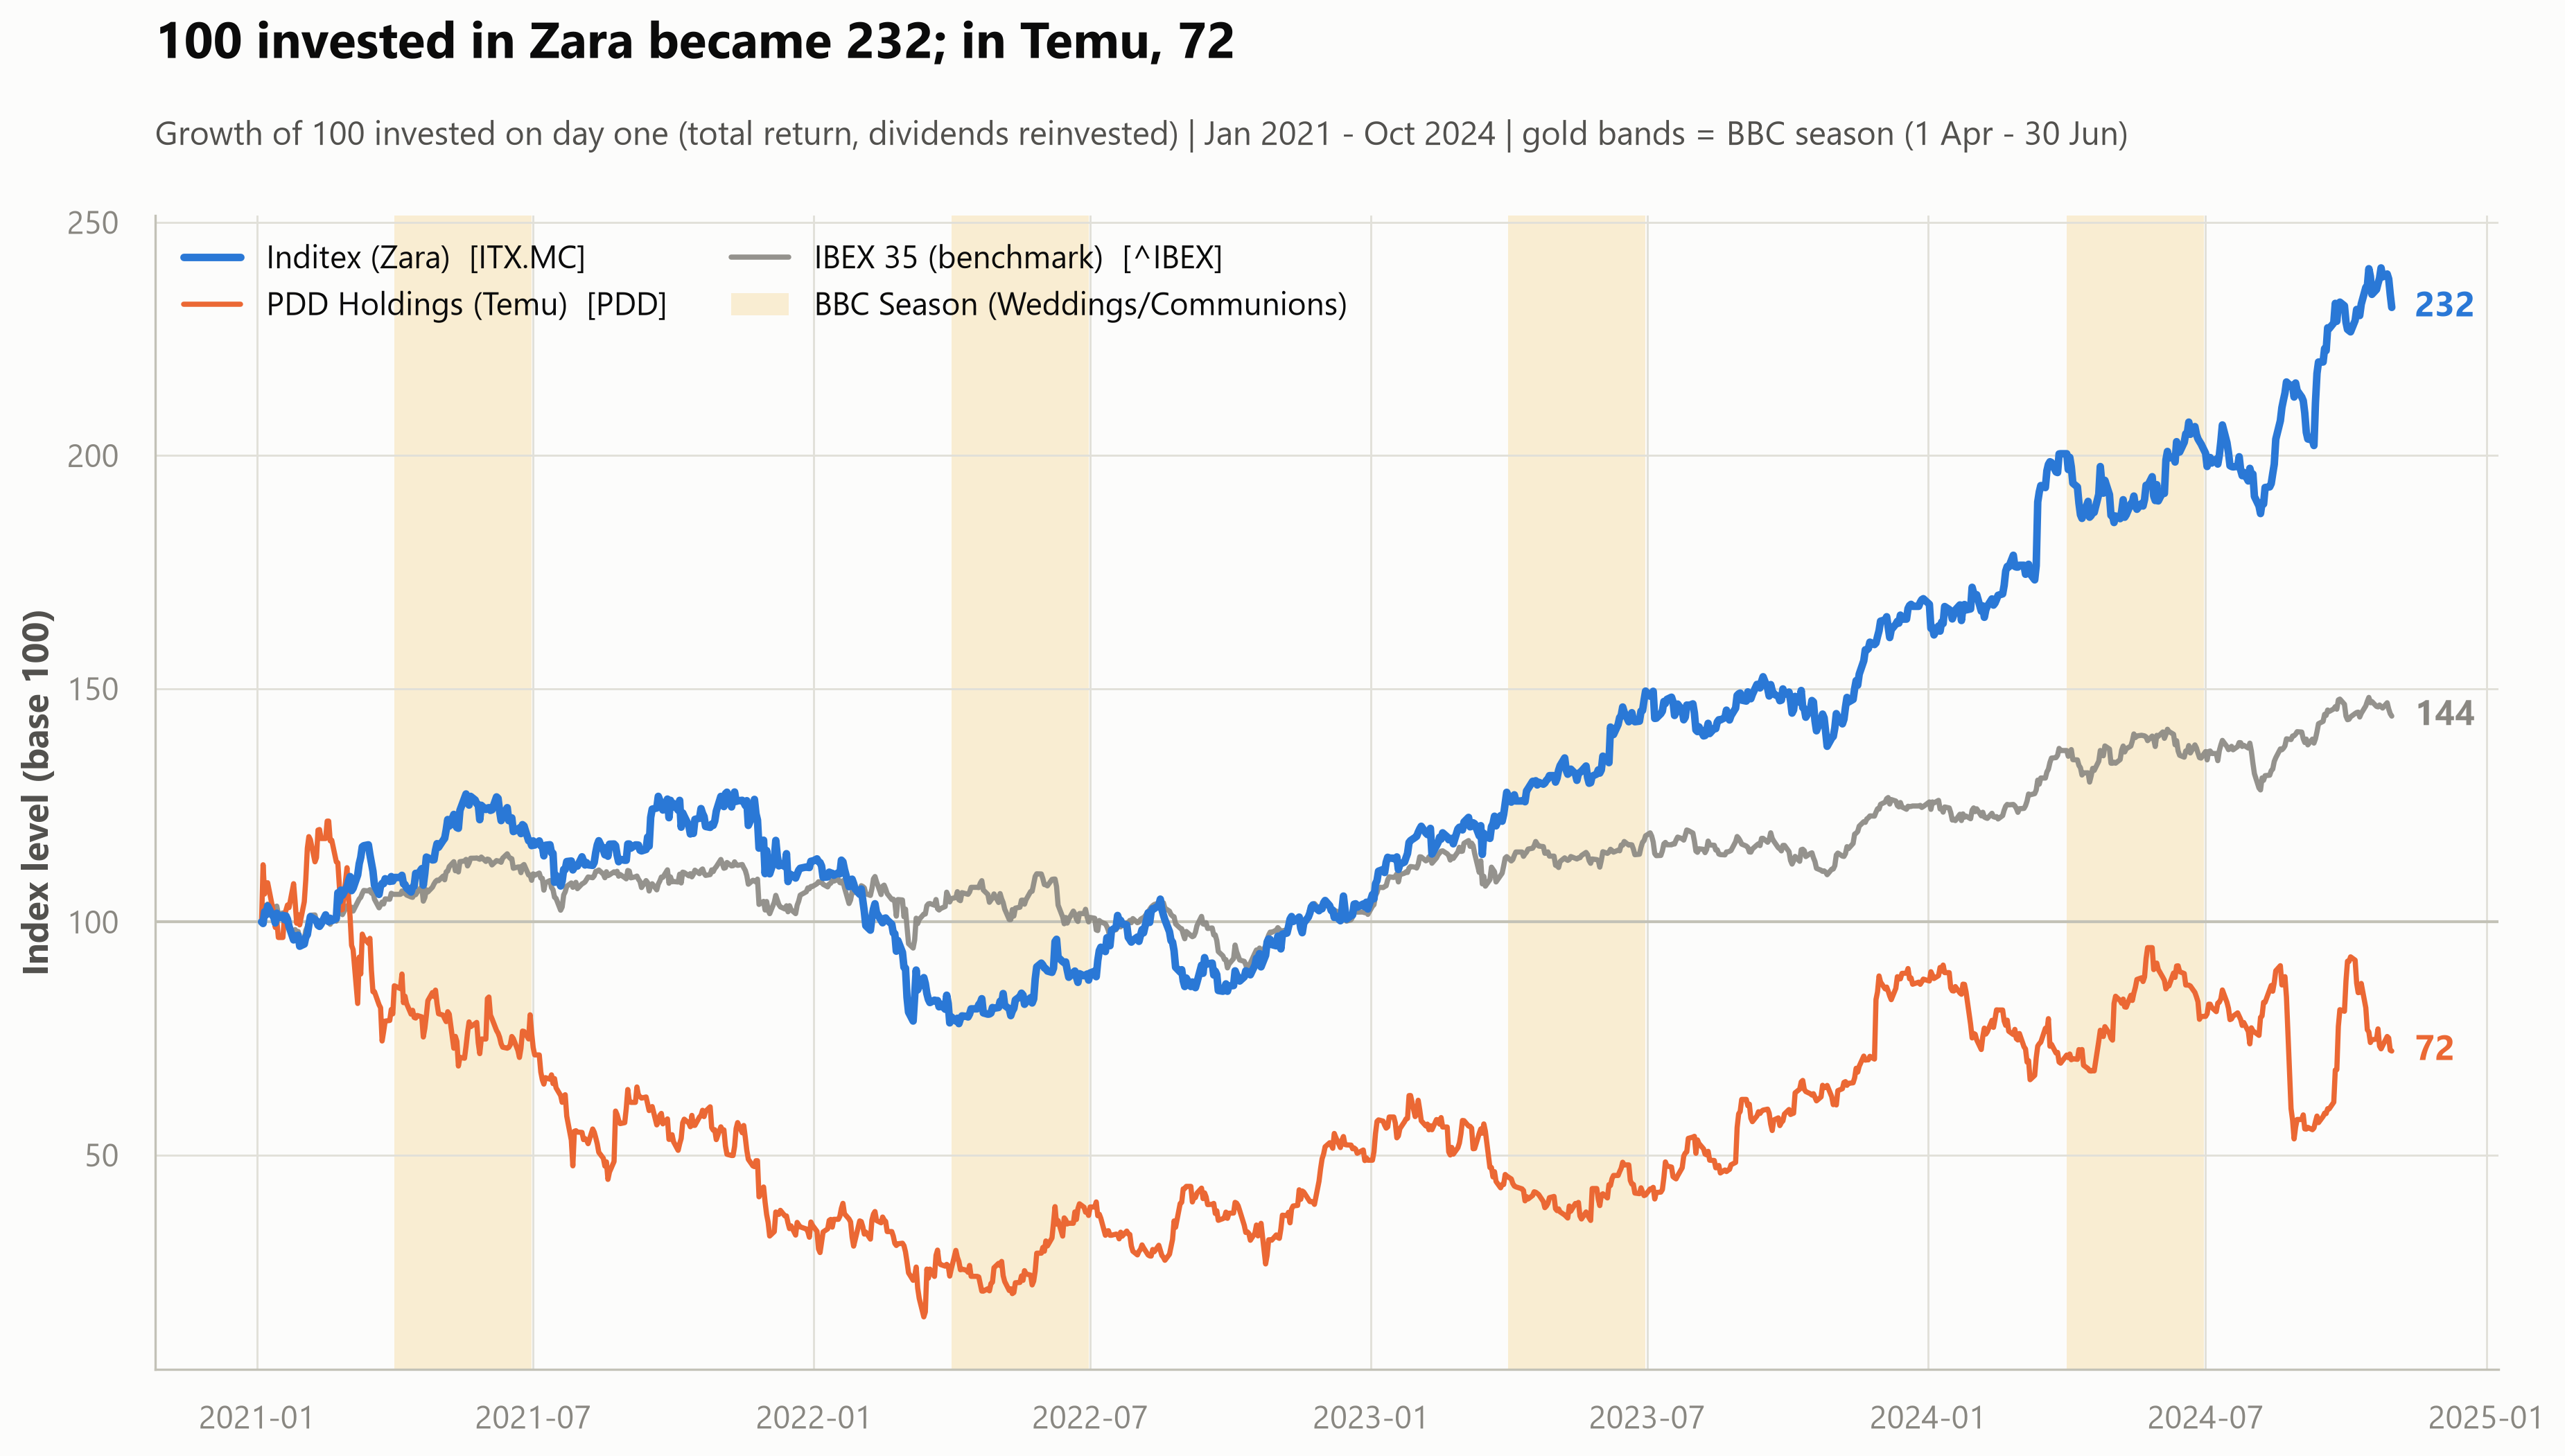

In [17]:
display(Image(filename=str(cfg.FIGURES_DIR / "01_H1_cumulative_returns.png"), width=1100))

**Gráfico 1 — H1.** 100 € invertidos el primer día se convierten en **232 €**
en Zara, **144 €** en el IBEX y **72 €** en Temu. Las bandas doradas marcan
cada temporada BBC. Obsérvese 2021–2022: Zara también sufre (cae hasta 80), lo
que confirma que no estamos ante una acción mágica, sino ante una que
**recupera**.

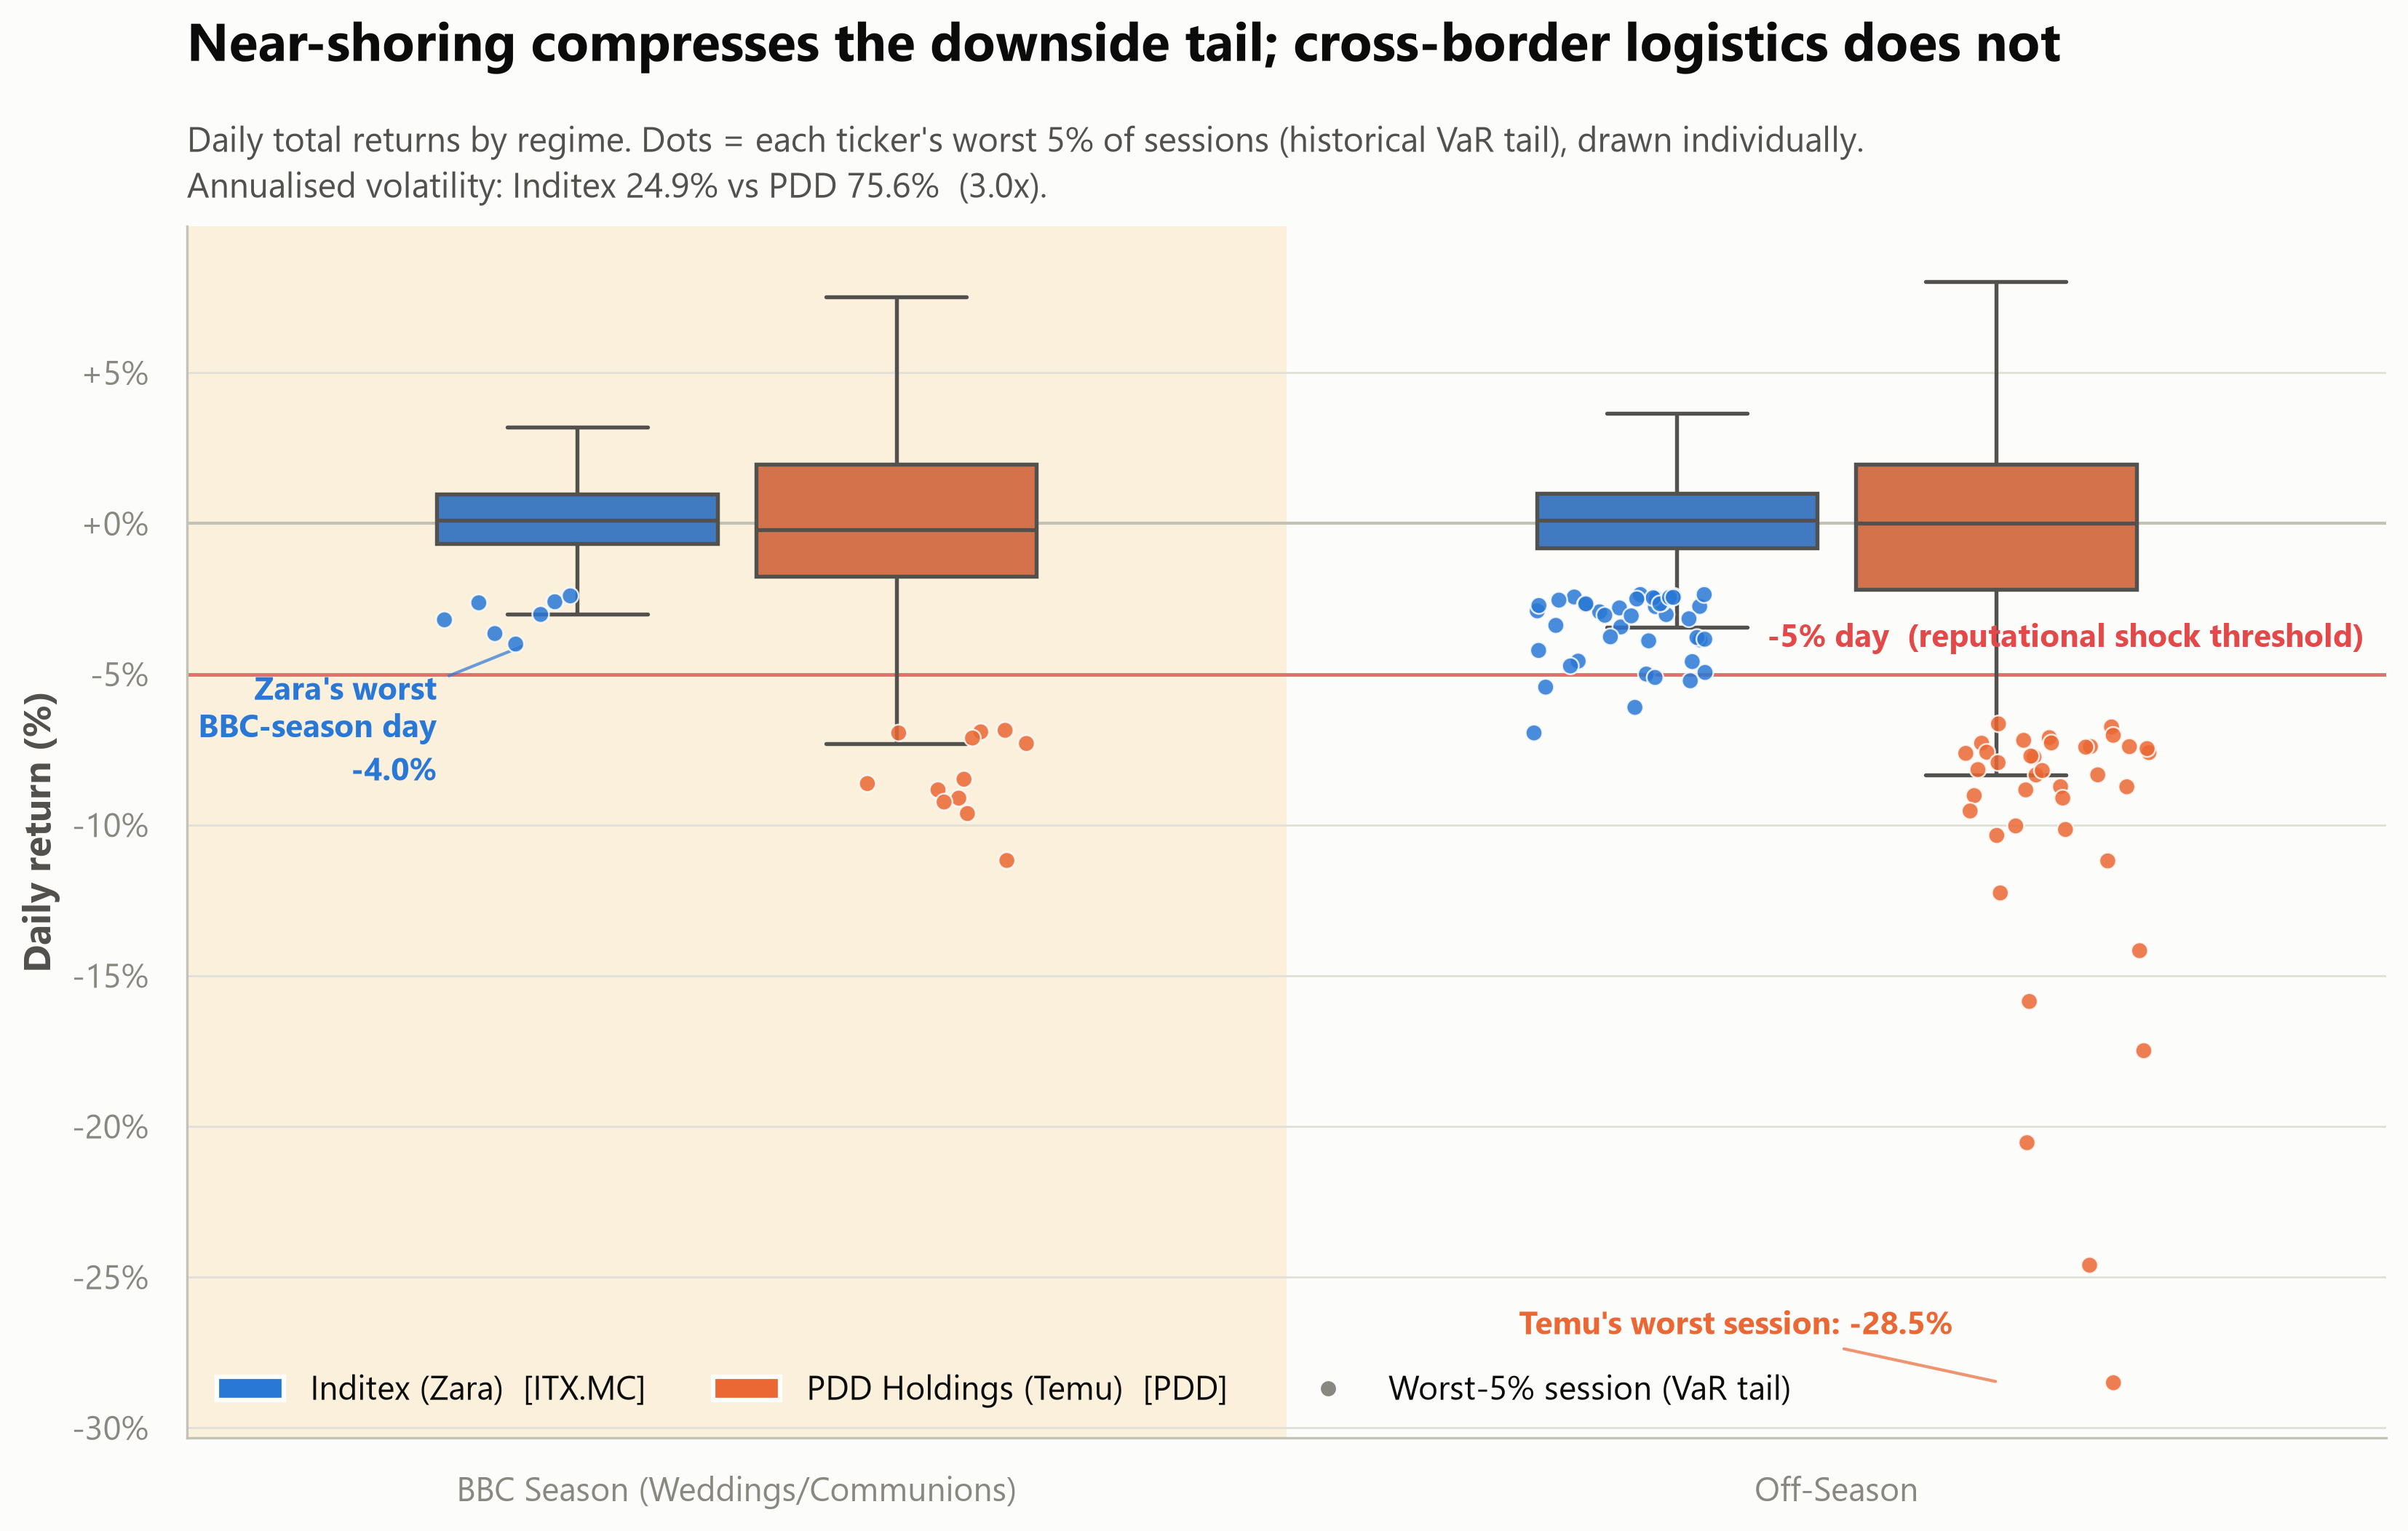

In [18]:
display(Image(filename=str(cfg.FIGURES_DIR / "02_H2_return_distributions.png"), width=1100))

**Gráfico 2 — H2.** Las cajas muestran el comportamiento normal; los puntos
son el peor 5% de sesiones de cada valor, dibujados uno a uno. Esa columna de
puntos naranjas descendiendo hasta −28,5% **es** la cadena de suministro
transfronteriza: cada punto es un arancel, una regla aduanera o un shock de
flete. Zara, en temporada de bodas, no tiene ni un solo día por debajo de −5%.

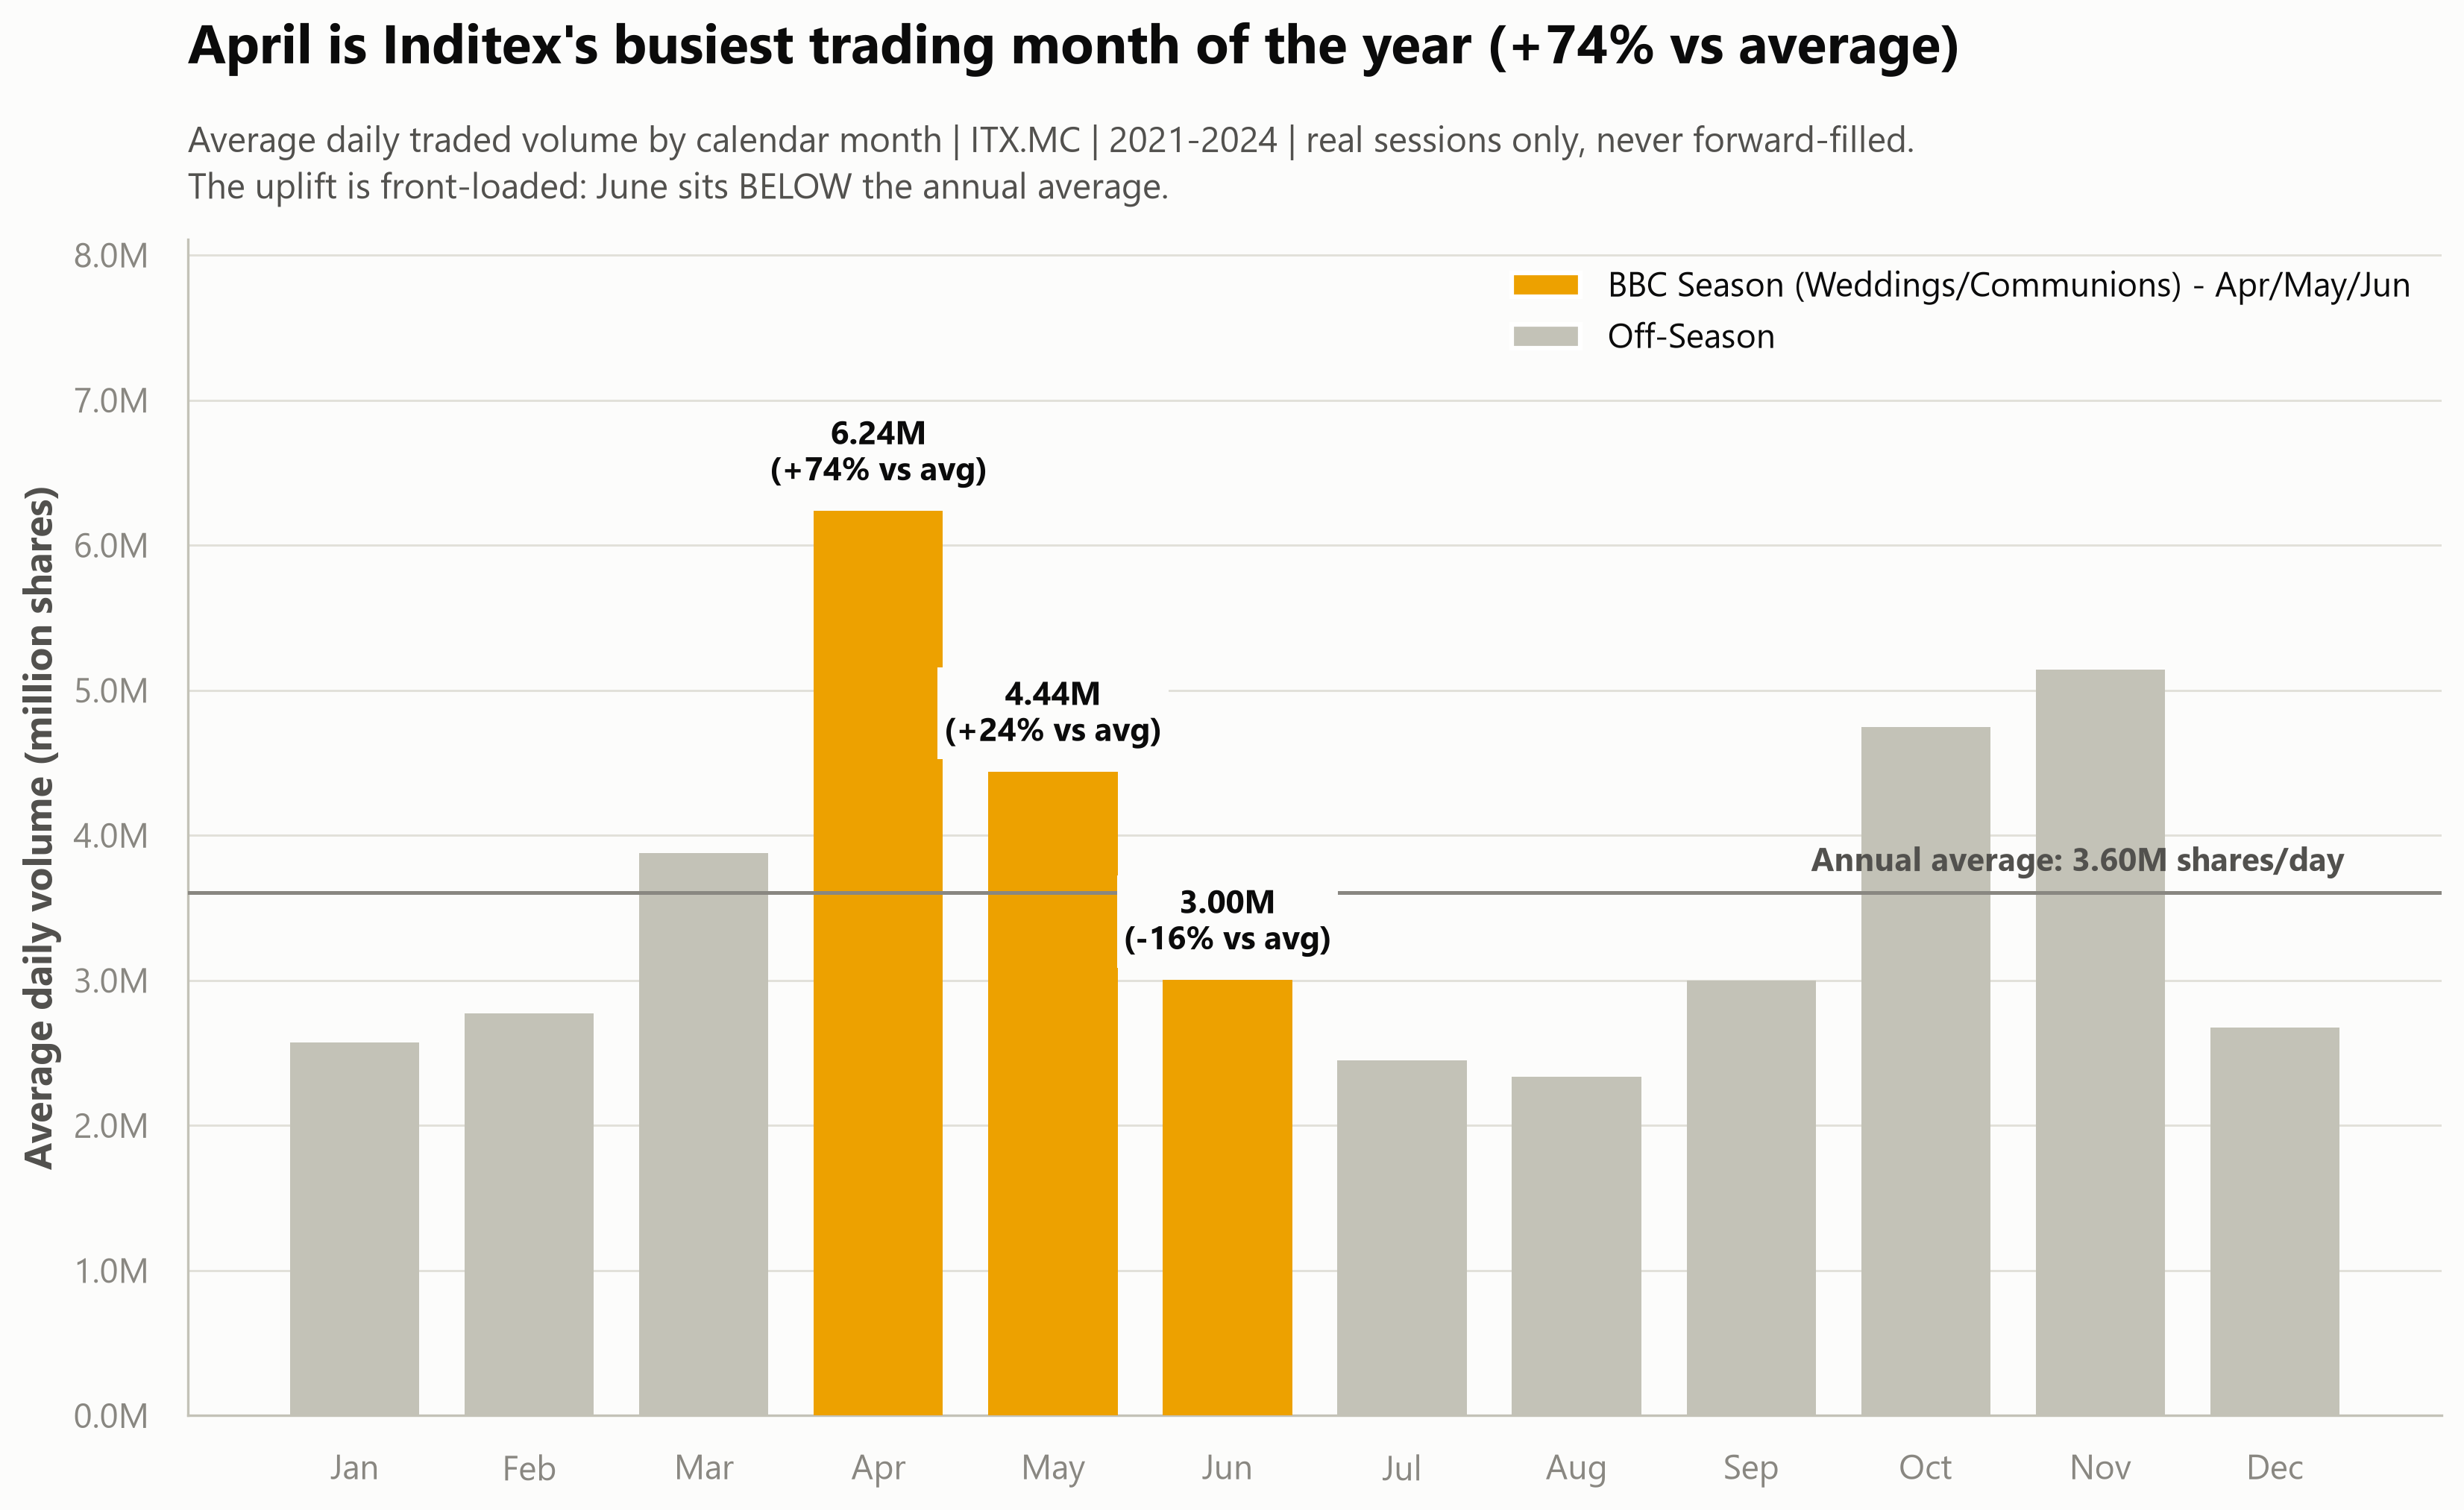

In [19]:
display(Image(filename=str(cfg.FIGURES_DIR / "03_H3_volume_seasonality.png"), width=1100))

**Gráfico 3 — H3.** Abril es el mes de mayor negociación del año para Inditex
(+74% sobre la media). El gráfico también muestra con honestidad el matiz:
junio queda por debajo de la media, y octubre–noviembre forman un segundo pico
que responde a resultados trimestrales y rebalanceos de índice, no a bodas.

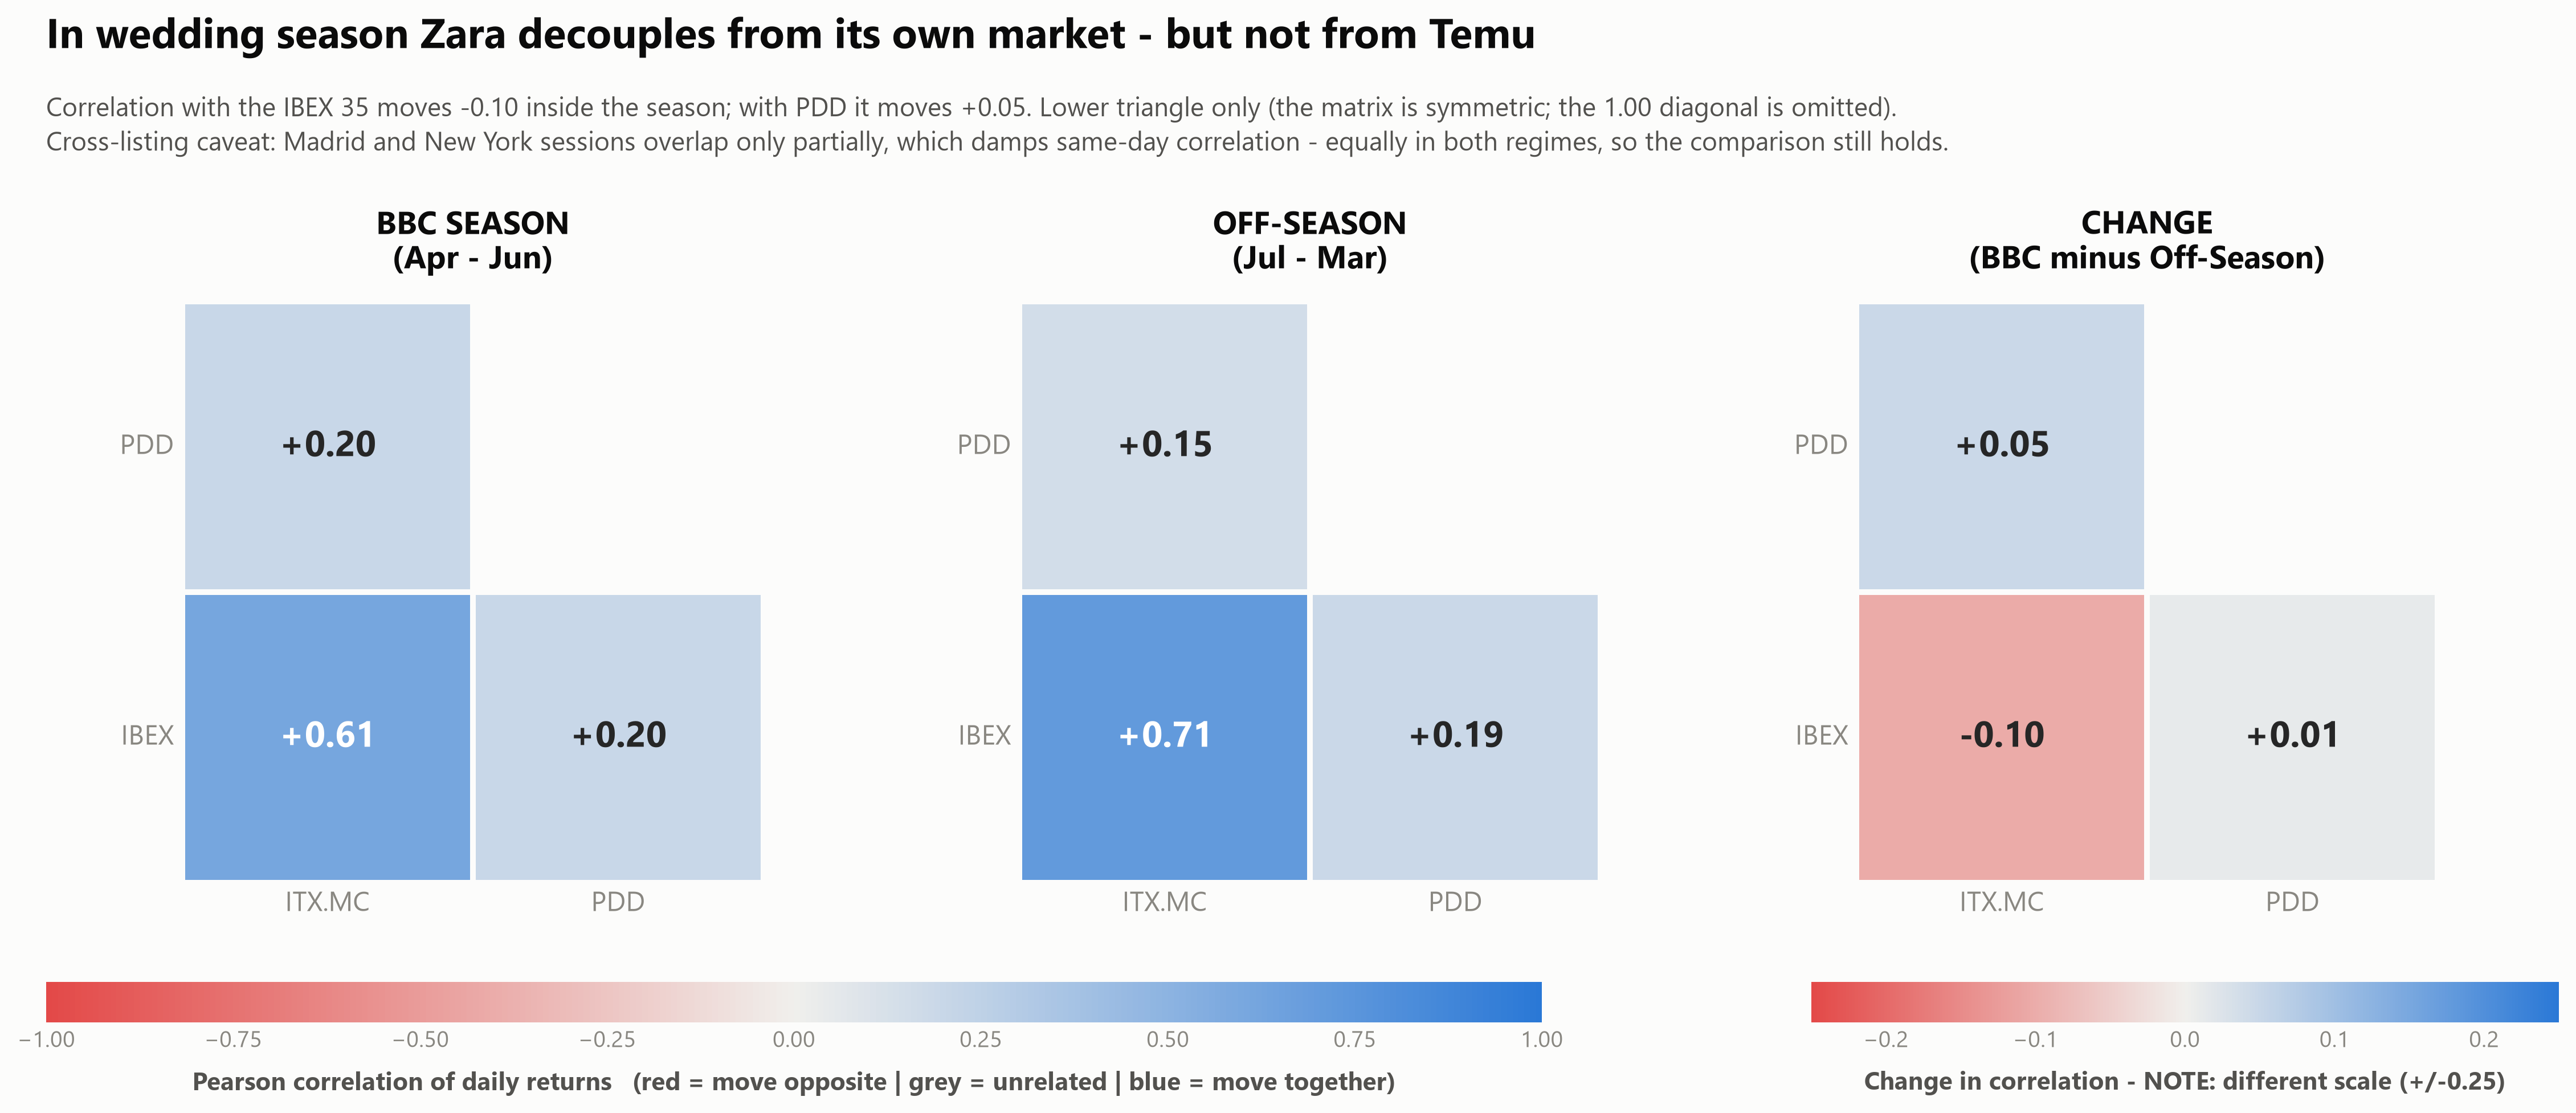

In [20]:
display(Image(filename=str(cfg.FIGURES_DIR / "04_SYNTHESIS_correlation_regimes.png"), width=1250))

**Gráfico 4 — Síntesis.** Una matriz de correlación responde a la pregunta
*"¿se mueven como un solo animal o como tres?"*. Los dos primeros paneles
comparten escala (−1 a +1) para que el ojo pueda compararlos; el tercer panel
mide una magnitud distinta (un *cambio* de correlación) y por eso lleva su
propia escala, etiquetada de forma explícita.

---
# 8. Conclusiones

In [21]:
results["verdicts"]

,Key evidence,Verdict
Hypothesis,,
H1 - Seasonal alpha vs IBEX and PDD,BBC-season excess vs ^IBEX: +13.52 bps/day (p=...,NOT SUPPORTED (data points the other way)
H2 - Lower volatility and fewer crash days than PDD,"Annualised vol 24.9% vs 75.6% (ratio 3.03x, Le...",SUPPORTED (direction + statistically significant)
H3 - Consistent Q2 volume buildup for Inditex,Q2 vs rest-of-year volume +38.3% (Welch p=0.00...,SUPPORTED (direction + statistically significant)


## 8.1 Las tres conclusiones de negocio

### 1. El near-shoring no se paga en rentabilidad, se paga en ausencia de sustos
Zara no batió a Temu durante la temporada BBC (H1 rechazada). Lo que sí hizo
fue entregar un **131,8%** de rentabilidad total con un **24,9%** de
volatilidad, frente a un **−27,7%** de PDD con un **75,6%**. Para un inversor
institucional con mandato de riesgo, eso no es una diferencia de grado: es una
diferencia de categoría de activo.

### 2. La cola izquierda es donde vive la cadena de suministro
87 sesiones por debajo del −5% en PDD frente a 5 en Inditex. Cero en Zara
durante la temporada de bodas. Cada uno de esos días de PDD tiene nombre:
cambio en el *de minimis* estadounidense, subida del flete aéreo, anuncio
arancelario. Un camión de Arteixo a Madrid no tiene ninguno de esos riesgos.

### 3. El dinero institucional llega en abril, no en junio
El volumen de Inditex sube un +38,3% en Q2, los 4 de 4 años, pero concentrado
en abril. El mercado compra la **expectativa** de la temporada de invitada, no
su resultado.

## 8.2 Oportunidades accionables

| Hallazgo | Acción para Inditex | Acción para un inversor |
|---|---|---|
| Abril es el pico de liquidez del año (+74%) | Ventana óptima para colocaciones, tramos de recompra o un *investor day* | Mejor momento para construir o deshacer posición con bajo impacto de mercado |
| Volatilidad 3× menor que el competidor | Argumento central del *equity story*: "entregamos moda rápida sin riesgo de cadena de suministro" | Candidata a la pata defensiva de una cartera de consumo discrecional |
| Desacoplamiento del IBEX en temporada (−0,10) | La temporada BBC es un motor **idiosincrático**: merece su propia línea de reporting | Fuente de diversificación dentro del propio mercado español |
| Cero días de desplome en temporada BBC | Fiabilidad de entrega como atributo de marca, no solo operativo | Riesgo de cola estacionalmente reducido |

## 8.3 Limitaciones (lo que este análisis NO demuestra)

Un EDA honesto declara sus límites:

1. **Correlación no es causalidad.** Hemos medido que el patrón existe, no que
   las bodas lo causen. Inditex es mucho más que España: la temporada BBC es
   una fracción de su negocio global.
2. **PDD es un proxy imperfecto de Shein.** Mismo modelo operativo, pero PDD
   incluye Pinduoduo (mercado doméstico chino), que no compite con Zara.
3. **Divisa local, no divisa común.** ITX.MC e ^IBEX cotizan en EUR y PDD en
   USD. Son rentabilidades tal y como las vive un inversor doméstico de cada
   mercado; convertir a una divisa única habría mezclado la volatilidad del
   EUR/USD en el perfil de riesgo de PDD y ya no estaríamos midiendo la cadena
   de suministro.
4. **Solapamiento parcial de sesiones.** Madrid y Nueva York comparten pocas
   horas: la correlación mismo-día entre ITX y PDD está mecánicamente
   infravalorada. El sesgo afecta por igual a ambos regímenes, así que la
   *comparación* temporada/fuera de temporada sigue siendo válida.
5. **Cuatro temporadas BBC.** Son 4 observaciones anuales. Es suficiente para
   un patrón de volumen que se repite 4/4, pero poco para un efecto de precio.
6. **Ventana marcada por el COVID y por la inflación de 2022.** El periodo
   incluye la reapertura post-pandemia y el shock inflacionista, ambos con
   efectos asimétricos sobre retail físico y e-commerce.

## 8.4 Próximos pasos

* Añadir **Shein** si llega a cotizar, y **H&M (`HM-B.ST`)** como segundo
  comparable occidental con cadena de suministro intermedia.
* Cruzar con datos de **búsquedas de Google Trends** para "vestido de invitada"
  y validar si el pico de volumen de abril sigue o precede al interés del
  consumidor.
* Incorporar **fechas de resultados trimestrales** como variable de control,
  para separar el efecto BBC del efecto "publicación de resultados" en el
  volumen de octubre y noviembre.
* Repetir H2 con una medida de volatilidad condicional (GARCH) en lugar de la
  desviación típica incondicional.

---

## Reproducibilidad

```bash
pip install -r requirements.txt
python src/main.py              # descarga datos frescos de Yahoo Finance
python src/main.py --offline    # reejecuta desde la caché en src/data/raw/
```

Todas las cifras de esta memoria se regeneran con esos comandos. Las tablas en
markdown quedan en `reports/tables/` y los gráficos a 300 DPI en
`reports/figures/`.